# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [8]:
airbnb = pd.read_csv("/content/listings (1).csv.gz")

airbnb.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,934859141300145599,https://www.airbnb.com/rooms/934859141300145599,20260622055616,2026-07-02,previous scrape,An Exquisite Rooftop Studio,Introducing an exquisite rooftop studio in the...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,384892315,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,944156894640610027,https://www.airbnb.com/rooms/944156894640610027,20260622055616,2026-06-23,city scrape,Tarrytown bungalow,Take a break and unwind at this peaceful oasis...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,13392053,...,5.00,4.75,4.25,NaN,NaN,1,0,1,0,0.12
2,1634902892490996951,https://www.airbnb.com/rooms/1634902892490996951,20260622055616,2026-06-23,city scrape,Central East Gem near running trail,Keep it simple at this peaceful and centrally-...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,266329439,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
3,1308737991593278409,https://www.airbnb.com/rooms/1308737991593278409,20260622055616,2026-06-23,city scrape,Empire,"- Accommodate up to 14 guests, 4-bedroom home<...",NaN,https://a0.muscache.com/pictures/miso/Hosting-...,398748229,...,4.93,4.80,4.61,OL2023119758,NaN,4,4,0,0,2.39
4,574582741829434703,https://www.airbnb.com/rooms/574582741829434703,20260622055616,2026-06-23,city scrape,Galaxy by AvantStay | Luxury Amenities in Austin,- Pet-friendly home<br />- Rooftop pool and lo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,434308464,...,4.52,4.97,4.90,NaN,NaN,178,178,0,0,0.60


## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

Columns with missing values (sorted descending):
neighborhood_overview           11295
host_since                      11295
host_total_listings_count       11295
neighbourhood                   11295
host_verifications              11295
host_response_rate              11295
host_acceptance_rate            11295
host_thumbnail_url              11295
host_response_time              11295
host_neighbourhood              11295
instant_bookable                11295
calendar_updated                11295
neighbourhood_group_cleansed    11295
license                          8211
host_about                       3868
host_location                    2294
review_scores_rating             1859
reviews_per_month                1859
review_scores_cleanliness        1859
last_review                      1859
dtype: int64


/tmp/ipykernel_251/1336317415.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_percent_filtered.index[:30], y=missing_percent_filtered.values[:30], palette="viridis")


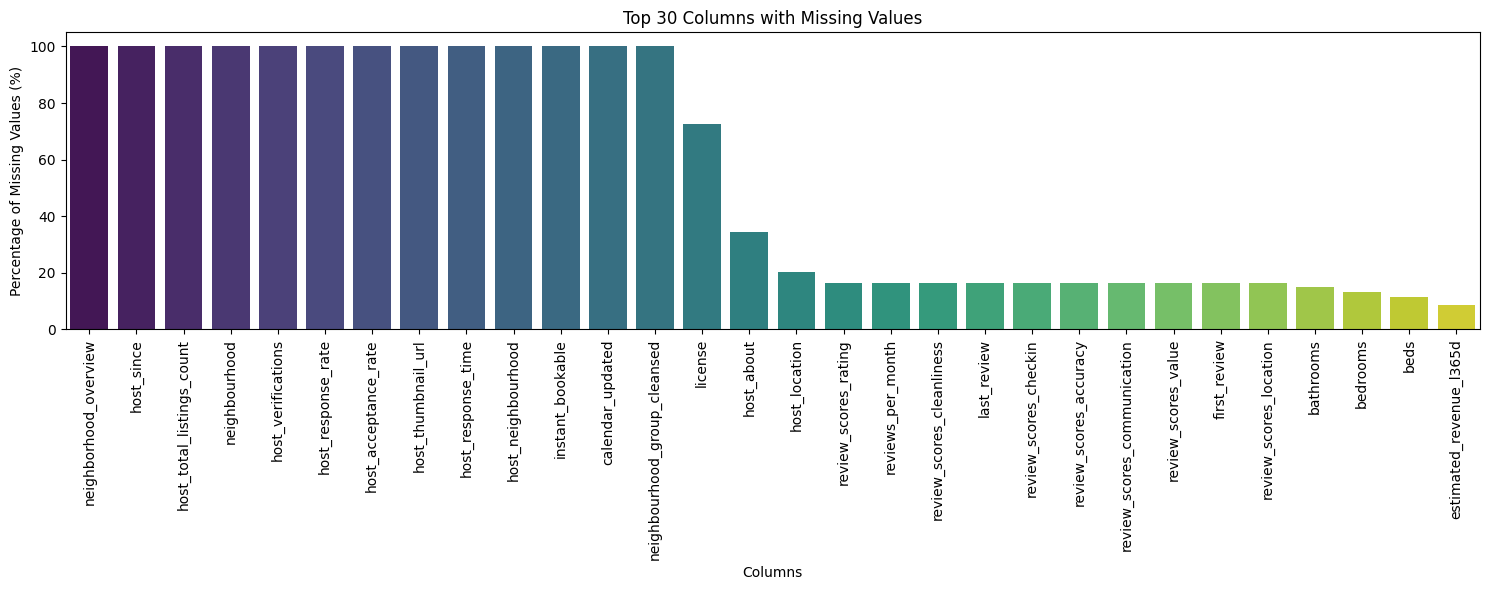

In [10]:
# 1. Count the null values of each column
missing_counts = airbnb.isnull().sum()
print("Columns with missing values (sorted descending):")
print(missing_counts[missing_counts > 0].sort_values(ascending=False).head(20))

# 2. Create visuals to show columns missing values
# We will filter to columns that have at least some missing values for a clearer visualization
missing_percentages = (airbnb.isnull().sum() / len(airbnb)) * 100
missing_percent_filtered = missing_percentages[missing_percentages > 0].sort_values(ascending=False)

plt.figure(figsize=(15, 6))
sns.barplot(x=missing_percent_filtered.index[:30], y=missing_percent_filtered.values[:30], palette="viridis")
plt.xticks(rotation=90)
plt.xlabel("Columns")
plt.ylabel("Percentage of Missing Values (%)")
plt.title("Top 30 Columns with Missing Values")
plt.tight_layout()
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. The top three columns with the most missing values were neighborhood_overview, host_since, and host_total_listings_count. Each of these had 11,295 missing values.

2. Missing host information, such as host_since and host_total_listings_count, could create business issues because it makes it harder to evaluate host experience and activity.

3. Columns that are completely empty and do not provide useful information, such as neighborhood_overview, calendar_updated, and neighbourhood_group_cleansed, could be safely dropped from the dataset.


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [11]:
# Define the columns to drop based on the prior analysis
columns_to_drop = ['neighborhood_overview', 'calendar_updated', 'neighbourhood_group_cleansed']

# Drop the columns from the dataset
airbnb = airbnb.drop(columns=columns_to_drop)

# Confirm they are gone by checking the dataset's remaining columns and shape
print(f"Dataset shape after dropping columns: {airbnb.shape}")
print("Are the dropped columns still in the dataset?")
print([col for col in columns_to_drop if col in airbnb.columns])

# Display the dataset info overview
airbnb.info(verbose=False)

Dataset shape after dropping columns: (11295, 87)
Are the dropped columns still in the dataset?
[]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11295 entries, 0 to 11294
Columns: 87 entries, id to reviews_per_month
dtypes: float64(40), int64(19), object(28)
memory usage: 7.5+ MB


### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped neighborhood_overview, calendar_updated, and neighbourhood_group_cleansed.

2. These columns were completely empty, with all 11,295 values missing. Since they contained no usable information, they would not help with analyzing listings, hosts, pricing, or performance.

3. Leaving completely empty columns in the dataset could make the data more confusing, increase unnecessary clutter, and cause problems in future analysis or dashboards.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [13]:
# 1. Clean 'review_scores_rating' (Numeric) using Median Imputation
# Find the median score
median_rating = airbnb['review_scores_rating'].median()
# Fill missing values with the median
airbnb['review_scores_rating'] = airbnb['review_scores_rating'].fillna(median_rating)

# 2. Clean 'host_location' (Categorical) using a placeholder flag
# Fill missing values with 'Unknown'
airbnb['host_location'] = airbnb['host_location'].fillna('Unknown')

# Confirm that there are no more missing values in these columns
print("Remaining missing values in 'review_scores_rating':", airbnb['review_scores_rating'].isnull().sum())
print("Remaining missing values in 'host_location':", airbnb['host_location'].isnull().sum())

# Display sample distribution of ratings and location counts
display(airbnb[['review_scores_rating', 'host_location']].head())

Remaining missing values in 'review_scores_rating': 0
Remaining missing values in 'host_location': 0


,review_scores_rating,host_location
0,4.93,Unknown
1,4.50,Unknown
2,4.93,"Austin, TX"
3,4.71,Unknown
4,4.84,"Austin, TX"


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. I cleaned review_scores_rating and host_location.

2. I filled missing review_scores_rating values with the median because it gives a reasonable middle value and is less affected by extreme ratings. I filled missing host_location values with "Unknown" because it would not make sense to guess a host's location.

3. One risk is that replacing missing review scores with the median can make some listings appear to have a rating they did not actually receive. Using "Unknown" for host location keeps the data complete, but it does not provide the actual missing location.


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

Summary Statistics for Cleaned Price Column:
count    10321.000000
mean       352.247362
std        828.970064
min          7.950000
25%        133.100000
50%        217.000000
75%        363.000000
max      58600.500000
Name: price, dtype: float64


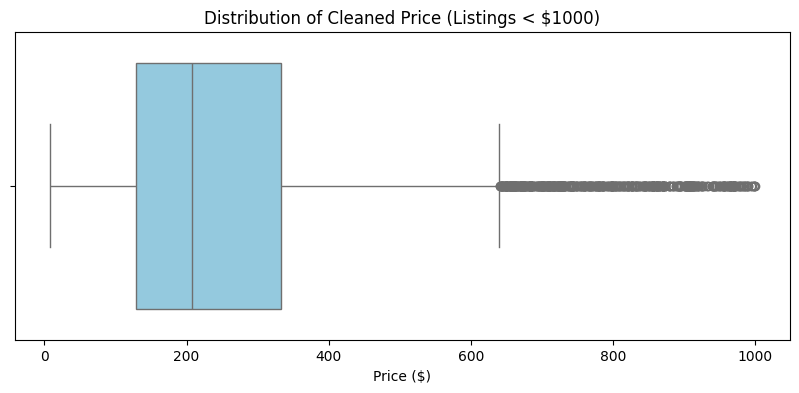

In [14]:
# 1. Clean and convert the 'price' column from string to float
# Remove dollar signs and commas, then cast to float
airbnb['price'] = airbnb['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)

# 2. Check work by summarizing the cleaned column
print("Summary Statistics for Cleaned Price Column:")
print(airbnb['price'].describe())

# 3. Plot a boxplot of prices under $1000 to better visualize the main distribution
plt.figure(figsize=(10, 4))
sns.boxplot(x=airbnb[airbnb['price'] < 1000]['price'], color='skyblue')
plt.title('Distribution of Cleaned Price (Listings < $1000)')
plt.xlabel('Price ($)')
plt.show()

### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. I fixed the price column.

2. I removed dollar signs and commas from the price values and converted the column from text into a numeric format.

3. Converting price into numeric data makes it possible to calculate averages, compare listings, create visualizations, and use price in future analysis.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [15]:
# 1. Check for exact duplicate rows in the dataset
exact_duplicates_count = airbnb.duplicated().sum()
print(f"Number of exact duplicate rows: {exact_duplicates_count}")

# 2. Check for duplicate IDs in the unique 'id' column
id_duplicates_count = airbnb.duplicated(subset=['id']).sum()
print(f"Number of duplicate listings based on 'id': {id_duplicates_count}")

# 3. Remove duplicates if found
if id_duplicates_count > 0:
    # Keep the first occurrence of each listing ID and drop others
    airbnb = airbnb.drop_duplicates(subset=['id'], keep='first')
    print("Duplicates removed successfully!")
else:
    print("No duplicate IDs found. No rows removed.")

# 4. Confirm unique count matches total length
print(f"Total unique IDs: {airbnb['id'].nunique()}")
print(f"Total rows remaining: {len(airbnb)}")

Number of exact duplicate rows: 0
Number of duplicate listings based on 'id': 0
No duplicate IDs found. No rows removed.
Total unique IDs: 11295
Total rows remaining: 11295


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. I did not find any exact duplicate rows or duplicate listing IDs in the dataset.

2. Since there were no duplicates, I kept all of the records. If duplicates had been found, I would have kept the first occurrence of each listing ID and removed the repeated records.

3. Duplicates are risky because they can inflate listing counts, distort averages such as price or ratings, and cause Airbnb teams to make decisions using inaccurate data.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [16]:
# Export the cleaned dataset to a CSV file
airbnb.to_csv('cleaned_airbnb_data_6.csv', index=False)
print("Dataset exported successfully as 'cleaned_airbnb_data_6.csv'!")

Dataset exported successfully as 'cleaned_airbnb_data_6.csv'!


## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. The most challenging part was deciding how to handle missing values. The coding itself was not too difficult, but applying the class concepts and deciding whether to fill, drop, or keep certain data took more thought.
2. One example was dropping columns like neighborhood_overview because they were completely empty. Keeping a column with no useful information would only add clutter and could make later analysis more confusing.  
3. A business team could benefit from the cleaned data by using it to compare prices, ratings, and listing information more accurately. Cleaner data can help them make better decisions without being misled by missing or inconsistent values.  
4. If I had more time, I would look more closely at extreme price outliers and other unusual values to decide whether they are valid listings or errors.  
5. This assignment relates to my customized learning outcome because it helped me practice working with real-world business data and preparing it for analysis. It showed me how cleaning data can make later analysis more accurate and useful for business decisions.  


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [24]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_06_data_cleaning.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tru

In [20]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful